In [53]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
df = pd.read_pickle(PROJECT_ROOT / 'data' / 'raw' / 'LSWMD_py3.pkl')
print(df.shape)

(811457, 6)


In [54]:
def unwrap(value):
    """[['Edge-Ring']] -> 'Edge-Ring',  [] -> None"""
    if isinstance(value, (np.ndarray, list)):
        arr = np.array(value, dtype=object).ravel()
        return str(arr[0]).strip() if arr.size > 0 else None
    if isinstance(value, str):
        return value.strip()
    return None

df['label'] = df['failureType'].apply(unwrap)
df['split'] = df['trianTestLabel'].apply(unwrap)   # 'Training' / 'Test' (original split)

print(df['label'].value_counts(dropna=False))

label
NaN          638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [55]:
import gc

labeled = df[df['label'].notna()][['waferMap', 'label', 'split']].reset_index(drop=True)
print('Labeled wafers:', len(labeled))

del df
gc.collect()   # frees several GB of RAM

Labeled wafers: 172950


0

In [56]:
import json

CLASSES = ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc',
           'Near-full', 'Random', 'Scratch', 'none']

label_to_id = {name: i for i, name in enumerate(CLASSES)}
labeled['label_id'] = labeled['label'].map(label_to_id)

assert labeled['label_id'].notna().all(), 'Found a label not in CLASSES'

with open(PROJECT_ROOT / 'data' / 'label_map.json', 'w') as f:
    json.dump(CLASSES, f, indent=2)

labeled[['label', 'label_id']].drop_duplicates().sort_values('label_id')

,label,label_id
43,Center,0
6492,Donut,1
35,Edge-Loc,2
97,Edge-Ring,3
19,Loc,4
814,Near-full,5
541,Random,6
130,Scratch,7
0,none,8


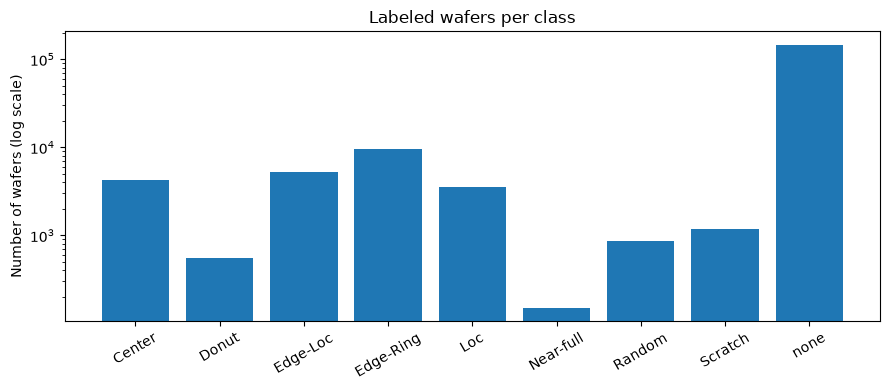

In [57]:
import matplotlib.pyplot as plt

counts = labeled['label'].value_counts().reindex(CLASSES)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(counts.index, counts.values)
ax.set_yscale('log')                      # log scale, or the small classes are invisible
ax.set_ylabel('Number of wafers (log scale)')
ax.set_title('Labeled wafers per class')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [58]:
labeled['rows'] = labeled['waferMap'].apply(lambda m: m.shape[0])
labeled['cols'] = labeled['waferMap'].apply(lambda m: m.shape[1])

print(labeled[['rows', 'cols']].describe())
print('Number of different sizes:', labeled.groupby(['rows', 'cols']).ngroups)

                rows           cols
count  172950.000000  172950.000000
mean       35.232807      34.822128
std        11.096015      11.876781
min        15.000000       3.000000
25%        27.000000      27.000000
50%        33.000000      33.000000
75%        41.000000      40.000000
max       212.000000     204.000000
Number of different sizes: 346


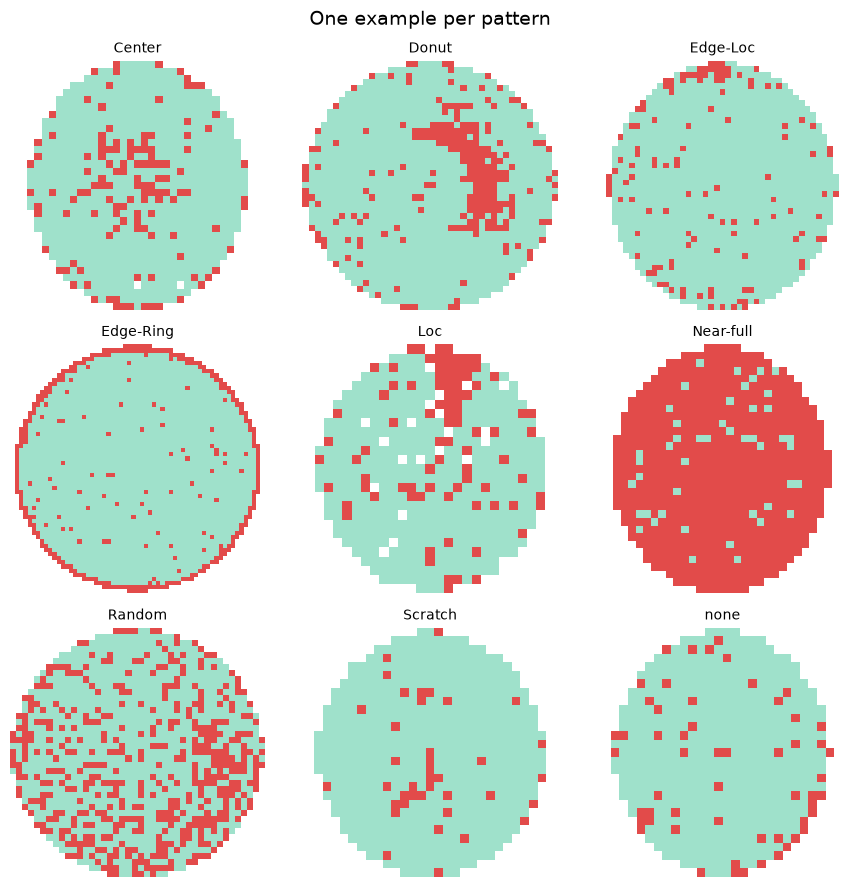

In [59]:
from matplotlib.colors import ListedColormap

WAFER_CMAP = ListedColormap(['white', '#9FE1CB', '#E24B4A'])   # 0, 1, 2

def show_wafer(ax, wafer_map, title=''):
    ax.imshow(wafer_map, cmap=WAFER_CMAP, vmin=0, vmax=2, interpolation='nearest')
    ax.set_title(title, fontsize=10)
    ax.axis('off')

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, name in zip(axes.ravel(), CLASSES):
    example = labeled[labeled['label'] == name].sample(1, random_state=42).iloc[0]
    show_wafer(ax, example['waferMap'], name)

plt.suptitle('One example per pattern', fontsize=14)
plt.tight_layout()
plt.show()

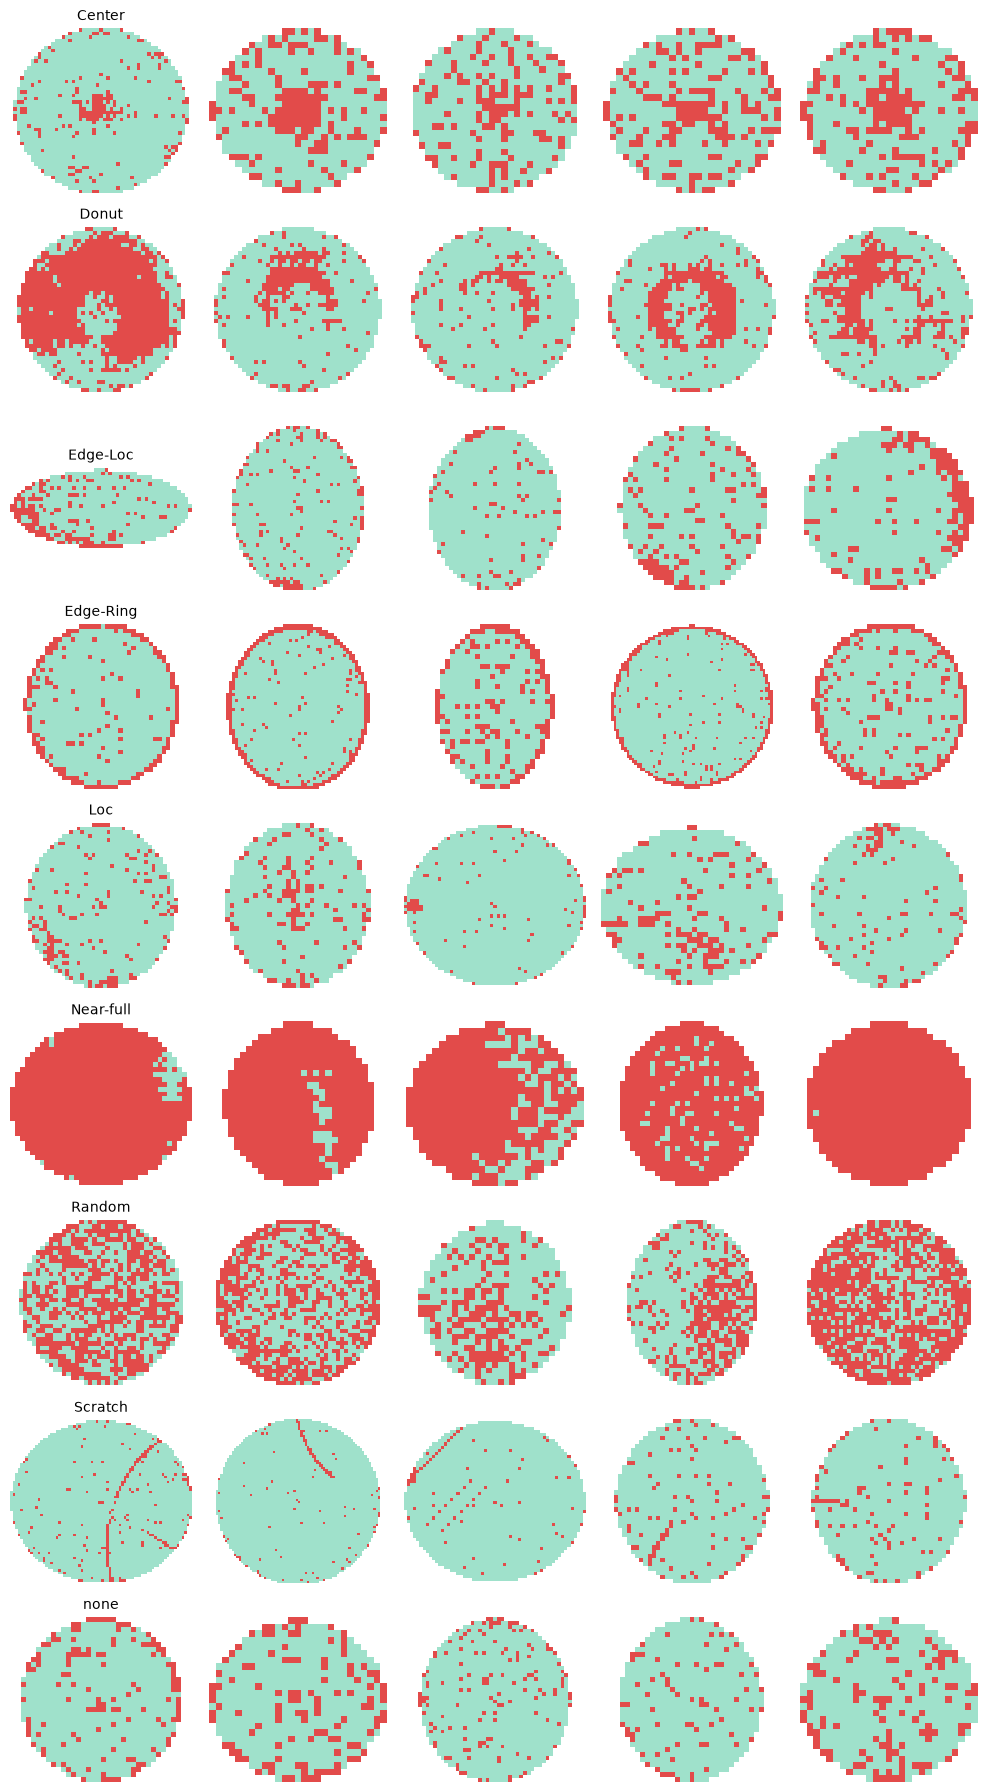

In [60]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(10, 18))
for row, name in enumerate(CLASSES):
    samples = labeled[labeled['label'] == name].sample(5, random_state=0)
    for col, (_, w) in enumerate(samples.iterrows()):
        show_wafer(axes[row, col], w['waferMap'], name if col == 0 else '')
plt.tight_layout()
plt.show()

In [61]:
(PROJECT_ROOT / 'data' / 'processed').mkdir(exist_ok=True)
labeled[['waferMap', 'label', 'label_id', 'split']].to_pickle(
    PROJECT_ROOT / 'data' / 'processed' / 'labeled.pkl'
)
print('Saved', len(labeled), 'labeled wafers')

Saved 172950 labeled wafers


In [62]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

print('labeled.pkl:', (PROJECT_ROOT / 'data' / 'processed' / 'labeled.pkl').exists())
print('label_map.json:', (PROJECT_ROOT / 'data' / 'label_map.json').exists())
print('charts:', (PROJECT_ROOT / 'docs' / 'pattern_examples.png').exists())

labeled.pkl: True
label_map.json: True
charts: False
